# Figure 2: EKE, growth rate and wavelength, with PV at three key times

Four-panel figure for one experiment (flat-bottom control, `test242`):
- **(a)** domain-integrated EKE $E(t)$ (left axis, log), growth rate and dominant wavelength $\hat\lambda=\lambda/L_{jet}$ (two right axes) against time in days. Vertical lines mark the reference time `idx0` ($t_0$, minimum of $E$), the time of peak growth rate `peak_tidx`, and the end of the eddy lifetime `idx_lifetime_end`.
- **(b, c, d)** surface PV at the same three times.

The PV time index in `ocean_interior.nc` is assumed to match the `u`/`v` time index in the catalog (checked below).

In [1]:
import glob, gc, warnings
from pathlib import Path
import intake, xarray as xr, xgcm
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from dask.distributed import Client
warnings.filterwarnings('ignore')
client = Client(); client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /proxy/8787/status,
Dashboard: /proxy/8787/status,Workers: 7
Total threads: 28,Total memory: 125.19 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:36631,Workers: 0
Dashboard: /proxy/8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:39609,Total threads: 4
Dashboard: /proxy/37429/status,Memory: 17.88 GiB
Nanny: tcp://127.0.0.1:35975,


## 1. Configuration

In [2]:
EXPERIMENT   = 'test242'
LABEL        = 'test242 300m'
ARCHIVE_ROOTS = [Path('/scratch/nm03/ae7501/mom6/archive'),
                 Path('/g/data/nm03/ae7501/mom6_outputs/from_scratch/idealized')]
CATALOG_PATH = f'intake_style_datastore/{EXPERIMENT}.json'

matches = [m for root in ARCHIVE_ROOTS for m in root.glob(f'{EXPERIMENT}-*')]
if not matches: raise FileNotFoundError(f'No experiment found for {EXPERIMENT}-*')
EXP_DIR     = matches[0]
OUTPUT_DIR  = EXP_DIR / 'output000'
STATIC_FILE = OUTPUT_DIR / 'ocean_static.nc'
IC_FILE     = OUTPUT_DIR / 'MOM_IC.nc'

# Growth-rate / EKE parameters
yh_slice = slice(170000, 200000)
time_indices = range(0, 4400)
check_window, sustain_window, sustain_tol = 10, 50, 0.0
PEAK_SEARCH_TSTART, PEAK_SEARCH_TEND = 200, 4400
tol_frac, max_gap = 0.1, 3
dx, wavelength_min, wavelength_max = 0.3, 2, 400

# PV panel parameters
ZL_INDEX  = 0
F_CORIOLIS = -1e-5
PV_VMIN, PV_VMAX = -2e-7, 0.0
PV_CMAP = 'Blues_r'
Y_CLIP_KM = (180, 220)
JET_WIDTH_M = 5000.0    # L_jet (m) of this experiment, for lambda / L_jet

# Optional manual key times, e.g. [300, 450, 600]; None = automatic
KEY_TIMES_OVERRIDE = None

OUT_DIR = Path('four_panel_plots'); OUT_DIR.mkdir(parents=True, exist_ok=True)

## 2. Static grid

In [3]:
ds_static = xr.open_dataset(STATIC_FILE).drop_vars(['time'], errors='ignore')
for c, kw in [('xh',dict(axis='X')),('xq',dict(axis='X',c_grid_axis_shift=0.5)),
              ('yh',dict(axis='Y')),('yq',dict(axis='Y',c_grid_axis_shift=0.5))]:
    ds_static.coords[c].attrs.update(**kw)
grid = xgcm.Grid(ds_static)
deptho = ds_static['deptho']

## 3. EKE, growth rate, dominant wavelength and key times

In [4]:
def smooth_gaussian(x, sigma=24):
    filled = np.where(np.isfinite(x), x, np.nanmean(x))
    return gaussian_filter1d(filled.astype(float), sigma=sigma)

def dominant_wavelength_from_power(power, wavelength, wl_min=wavelength_min, wl_max=wavelength_max):
    ok = (wavelength >= wl_min) & (wavelength <= wl_max)
    if not ok.any(): return np.nan
    return wavelength[ok][np.argmax(power[ok])]

esm_ds = intake.open_esm_datastore(CATALOG_PATH,
    columns_with_iterables=["variable","variable_long_name","variable_standard_name",
                            "variable_cell_methods","variable_units"])
u = esm_ds.search(variable='u').to_dask()['u']
v = esm_ds.search(variable='v').to_dask()['v']
u = u.chunk({d:-1 for d in u.dims if d in ('xh','xq')})
v = v.chunk({d:-1 for d in v.dims if d in ('yh','yq')})
u_int = grid.interp(u, 'X', boundary='extend')
v_int = grid.interp(v, 'Y', boundary='extend')
u_red = u_int.sum(dim='zl').sel(yh=yh_slice)
v_red = v_int.sum(dim='zl').sel(yh=yh_slice)
u_p = u_red - u_red.mean(dim='xh')
v_p = v_red - v_red.mean(dim='xh')

n_time = u_int.sizes['time']
loop_indices = [t for t in time_indices if t < n_time]
u_p_np = u_p.isel(time=loop_indices).compute().values

# Dominant wavelength from the y-summed power spectrum of u'
freq_x = np.fft.rfftfreq(u_p_np.shape[-1], d=dx)
with np.errstate(divide='ignore'):
    wavelength_x = np.where(freq_x != 0, 1.0/freq_x, np.inf)
dwl_arr = np.array([dominant_wavelength_from_power(
    (np.abs(np.fft.rfft(u_p_np[i], axis=-1))**2).sum(axis=0), wavelength_x)
    for i in range(len(loop_indices))])
times_arr = np.array(loop_indices)

# EKE
eke = (0.5*(u_p**2 + v_p**2)).mean(dim='xh').sum(dim='yh').compute()
E = eke.values.astype(np.float64)
dt_sec = (eke.time.values - eke.time.values[0]).astype('timedelta64[s]').astype(np.float64)

# idx0: first local minimum of E followed by sustained growth
local_min = np.where((E[1:-1] < E[:-2]) & (E[1:-1] < E[2:]))[0] + 1
idx0 = None
for cand in local_min:
    if cand + check_window >= len(E): break
    w = E[cand:cand+check_window+1]
    if np.polyfit(np.arange(len(w)), w, 1)[0] <= 0: continue
    if np.any(E[cand:min(cand+sustain_window, len(E))] < E[cand] - sustain_tol): continue
    idx0 = cand; break
if idx0 is None:
    idx0 = 1 + np.argmin(E[1:]); print('fallback to global-min idx0')

# growth rate
growth_raw = np.full_like(E, np.nan)
dtr = dt_sec - dt_sec[idx0]
valid = (dtr > 0) & (E > 0)
growth_raw[valid] = np.log(E[valid]/E[idx0]) / (2*dtr[valid])
growth = smooth_gaussian(growth_raw, sigma=24)

# peak
lo, hi = max(PEAK_SEARCH_TSTART, idx0), min(PEAK_SEARCH_TEND, len(growth))
peak_tidx = lo + int(np.nanargmax(growth[lo:hi])) if hi > lo else idx0

# Lifetime end: last time the peak-growth wavelength stays within tol_frac
pos0 = int(np.argmin(np.abs(times_arr - peak_tidx)))
lam_peak = dwl_arr[pos0]; tol = tol_frac*lam_peak
idx_lifetime_end, gap = int(times_arr[pos0]), 0
for pos in range(pos0, len(dwl_arr)):
    if abs(dwl_arr[pos]-lam_peak) <= tol: idx_lifetime_end, gap = int(times_arr[pos]), 0
    else:
        gap += 1
        if gap > max_gap: break

key_times = KEY_TIMES_OVERRIDE or [idx0, peak_tidx, idx_lifetime_end]
key_names = ['idx0', 'peak growth rate', 'lifetime end']
print('key times:', dict(zip(key_names, key_times)), '| lambda_peak =', lam_peak)

key times: {'idx0': np.int64(17), 'peak growth rate': 331, 'lifetime end': 488} | lambda_peak = 71.39999999999999


## 4. Load PV at the key times

In [5]:
files = sorted(glob.glob(str(EXP_DIR / 'output*' / 'ocean_interior.nc')))
if not files: raise FileNotFoundError('no ocean_interior.nc found')
pv_full = xr.open_mfdataset(files, combine='by_coords')['PV']
print('PV time steps:', len(pv_full.time), '| u/v time steps:', n_time)
if len(pv_full.time) != n_time:
    print('[WARN] PV and u/v have different time lengths -- check the time index mapping!')
valid_times = [t for t in key_times if t < len(pv_full.time)]
sel = dict(time=valid_times);
if 'zl' in pv_full.dims: sel['zl'] = ZL_INDEX
pv_sel = pv_full.isel(**sel).compute()
print('pv_sel', pv_sel.shape)

PV time steps: 1416 | u/v time steps: 1416


2026-10-26 19:35:52,025 - distributed.worker.memory - WARNING - Unmanaged memory use is high. This may indicate a memory leak or the memory may not be released to the OS; see https://distributed.dask.org/en/latest/worker-memory.html#memory-not-released-back-to-the-os for more information. -- Unmanaged memory: 12.71 GiB -- Worker memory limit: 17.88 GiB
2026-10-26 19:35:53,951 - distributed.worker.memory - WARNING - Worker is at 80% memory usage. Pausing worker.  Process memory: 14.35 GiB -- Worker memory limit: 17.88 GiB
2026-10-26 19:35:55,423 - distributed.worker.memory - WARNING - Worker is at 37% memory usage. Resuming worker. Process memory: 6.64 GiB -- Worker memory limit: 17.88 GiB


pv_sel (3, 1334, 1667)


## 5. Plot

Eddy spacing = 71.4 km; centres at [ 60.5 132.  203.4 274.9 346.3 417.8 489.2]


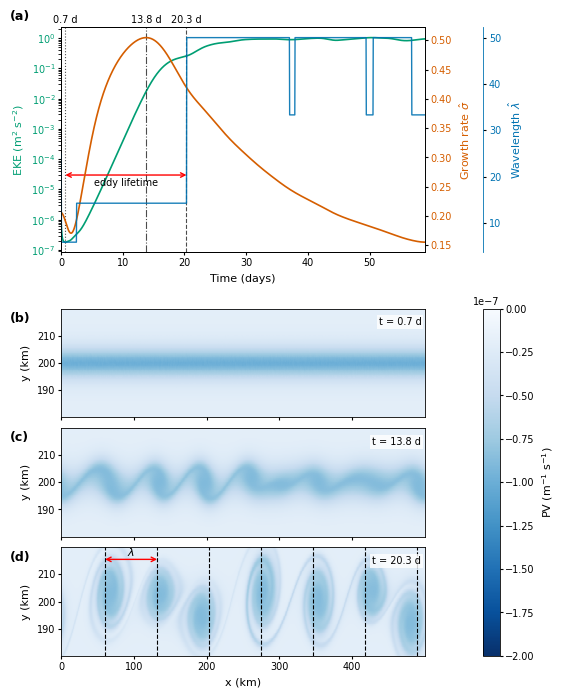

Saved /home/130/ae7501/four_panel_plots/four_panel_test242.png


In [6]:
# Font sizes
ft_size, ft_small = 8, 7
plt.rcParams.update({
    'font.size': ft_size, 'axes.titlesize': ft_size, 'axes.labelsize': ft_size,
    'xtick.labelsize': ft_small, 'ytick.labelsize': ft_small, 'legend.fontsize': ft_size,
    'xtick.major.size': 2.5, 'ytick.major.size': 2.5,
    'xtick.major.pad': 1.5, 'ytick.major.pad': 1.5, 'axes.linewidth': 0.6,
})

# Time axis in days
t_days    = dt_sec / 86400.0
wl_days   = t_days[times_arr]
growth_nd = growth / abs(F_CORIOLIS)                 # sigma / |f|
wl_nd     = dwl_arr * 1e3 / JET_WIDTH_M              # lambda / L_jet
key_days  = [t_days[t] for t in key_times]

x_name = 'xh' if 'xh' in pv_sel.coords else 'xq'
y_name = 'yh' if 'yh' in pv_sel.coords else 'yq'
x_km = pv_sel[x_name].values/1e3; y_km = pv_sel[y_name].values/1e3
ysel = (y_km >= Y_CLIP_KM[0]) & (y_km <= Y_CLIP_KM[1])

C_EKE, C_GR, C_WL = '#009E73', '#D55E00', '#0072B2'

# Layout (figure fractions)
FIG_W, FIG_H = 6.5, 7.5            # inches -- portrait
L, R_MAIN    = 0.12, 0.68          # left / right edge of all main axes
WL_OFFSET_PT = 42                  # outward offset of the wavelength axis (points)
x_wl  = R_MAIN + WL_OFFSET_PT/72/FIG_W   # figure-x of the wavelength axis = colorbar left edge
CB_W  = 0.025
A_BOTTOM, A_H = 0.67, 0.30                       # panel (a): taller
PV_TOP, PV_H, PV_GAP = 0.595, 0.145, 0.014          # PV panels: shorter

fig = plt.figure(figsize=(FIG_W, FIG_H))
ax = fig.add_axes([L, A_BOTTOM, R_MAIN-L, A_H])
pv_rects = [[L, PV_TOP - (k+1)*PV_H - k*PV_GAP, R_MAIN-L, PV_H] for k in range(3)]

# (a) EKE (left) + growth rate (right) + wavelength (second right axis)
ax.plot(t_days, np.maximum(E, 1e-30), color=C_EKE, lw=1.2); ax.set_yscale('log')
ax.set_xlabel('Time (days)'); ax.set_ylabel('EKE (m$^2$ s$^{-2}$)', color=C_EKE)
ax.tick_params(axis='y', labelcolor=C_EKE)
ax2 = ax.twinx()
ax2.plot(t_days, growth_nd, color=C_GR, lw=1.2)
ax2.set_ylabel(r'Growth rate $\hat{\sigma}$', color=C_GR)
ax2.tick_params(axis='y', labelcolor=C_GR)
ax3 = ax.twinx()
ax3.spines['right'].set_position(('outward', WL_OFFSET_PT))
ax3.plot(wl_days, wl_nd, color=C_WL, lw=1.0, alpha=0.9)
ax3.set_ylabel(r'Wavelength $\hat{\lambda}$', color=C_WL)
ax3.tick_params(axis='y', labelcolor=C_WL)
ax3.spines['right'].set_edgecolor(C_WL)
for td, ls in zip(key_days, [':', '-.', '--']):
    ax.axvline(td, color='k', ls=ls, lw=0.8, alpha=0.7)
    ax.text(td, 1.01, f'{td:.1f} d', transform=ax.get_xaxis_transform(), ha='center', va='bottom', fontsize=ft_small)
ax.set_xlim(t_days[0], t_days[-1])
ax.text(-0.14, 1.02, '(a)', transform=ax.transAxes, fontweight='bold', fontsize=ft_size+1, va='bottom')

# (b, c, d) PV, clipped in y and stacked
vmin = PV_VMIN if PV_VMIN is not None else np.nanpercentile(pv_sel.values, 5)
vmax = PV_VMAX if PV_VMAX is not None else np.nanpercentile(pv_sel.values, 95)
axes_pv = []
for k, t in enumerate(valid_times):
    axp = fig.add_axes(pv_rects[k], sharex=axes_pv[0] if axes_pv else None)
    im = axp.pcolormesh(x_km, y_km[ysel], pv_sel.isel(time=k).values[ysel, :],
                        cmap=PV_CMAP, vmin=vmin, vmax=vmax, shading='auto', rasterized=True)
    axp.set_ylim(*Y_CLIP_KM); axp.set_ylabel('y (km)')
    axp.set_yticks([190, 200, 210])
    axp.text(-0.14, 0.97, '(' + 'bcd'[k] + ')', transform=axp.transAxes, fontweight='bold', fontsize=ft_size+1, va='top')
    axp.text(0.99, 0.92, f't = {key_days[k]:.1f} d', transform=axp.transAxes, ha='right', va='top',
             fontsize=ft_small, bbox=dict(fc='w', ec='none', alpha=0.8, pad=1.5))
    if k < len(valid_times)-1: plt.setp(axp.get_xticklabels(), visible=False)
    axes_pv.append(axp)
axes_pv[-1].set_xlabel('x (km)')

# Annotations
C_ARROW = 'red'
# (a) eddy lifetime arrow
Y_LIFE = 3e-5                                   # EKE-axis height of the arrow
ax.annotate('', xy=(key_days[0], Y_LIFE), xytext=(key_days[-1], Y_LIFE),
            arrowprops=dict(arrowstyle='<->', color=C_ARROW, lw=1.0, shrinkA=0, shrinkB=0))
ax.annotate('eddy lifetime', xy=(0.5*(key_days[0] + key_days[-1]), Y_LIFE), xytext=(0, -2),
            textcoords='offset points', ha='center', va='top', color='k', fontsize=ft_small)

# (d) equally spaced eddy-centre lines (phase fitted to the PV cores) and wavelength arrow
N_EDDY = 7                                      # number of eddies in the domain at the last snapshot
axd = axes_pv[-1]
dx_km = np.median(np.diff(x_km)); Lx_km = x_km[-1] - x_km[0] + dx_km
spacing_km = Lx_km / N_EDDY
core = np.nanmin(pv_sel.isel(time=len(valid_times)-1).values[ysel, :], axis=0)
offsets = np.linspace(0, spacing_km, 400, endpoint=False)
score = [np.interp(x_km[0] + o + spacing_km*np.arange(N_EDDY), x_km, core, period=Lx_km).sum() for o in offsets]
x_c = x_km[0] + offsets[int(np.argmin(score))] + spacing_km*np.arange(N_EDDY)
for xc in x_c:
    axd.axvline(xc, color='k', ls='--', lw=0.8)
Y_LAM = 215.5                                   # y (km) of the wavelength arrow
axd.annotate('', xy=(x_c[0], Y_LAM), xytext=(x_c[1], Y_LAM),
             arrowprops=dict(arrowstyle='<->', color=C_ARROW, lw=1.0, shrinkA=0, shrinkB=0))
axd.text(0.5*(x_c[0] + x_c[1]), Y_LAM + 0.5, r'$\lambda$', ha='center', va='bottom', color='k', fontsize=ft_size)
print(f'Eddy spacing = {spacing_km:.1f} km; centres at', np.round(x_c, 1))

# Colorbar aligned with the wavelength axis, spanning the three PV panels
cb_bottom = pv_rects[-1][1]; cb_top = pv_rects[0][1] + PV_H
cax = fig.add_axes([x_wl, cb_bottom, CB_W, cb_top - cb_bottom])
cb = fig.colorbar(im, cax=cax)
cb.ax.tick_params(labelsize=ft_small)
cb.set_label('PV (m$^{-1}$ s$^{-1}$)', fontsize=ft_size)

fname = OUT_DIR / f'four_panel_{EXPERIMENT}.png'
fig.savefig(fname, dpi=300, bbox_inches='tight', pad_inches=0.02); plt.show(); print('Saved', fname.resolve())